,Кількість завдань,"Середній час реакції, мс","95-й перцентиль, мс","Середній час очікування, мс","Виконано вчасно, %",Порушення дедлайну,"Середнє перевищення дедлайну, мс"
FIFO,2487.0,426.96,1306.50,111.67,51.47,1207.0,182.09
Priority,2487.0,462.41,1498.52,147.16,50.14,1240.0,196.21
Adaptive,2487.0,433.58,1392.02,119.45,54.80,1124.0,205.14


FIFO


,Завдань,Середній_час_реакції,Середній_час_очікування,Вчасно_відсотків
type,,,,
T1,841,217.75,131.96,49.23
T2,891,870.16,102.58,13.80
T3,755,136.95,99.80,98.41


Priority


,Завдань,Середній_час_реакції,Середній_час_очікування,Вчасно_відсотків
type,,,,
T1,841,139.81,53.42,51.96
T2,891,870.13,102.48,14.93
T3,755,340.59,304.30,89.67


Adaptive


... (3 outputs left out)

Priority


,Сервер,Кількість завдань,"Час роботи, мс","Завантаження, %"
0,Edge-1,856,212820.856869,70.815013
1,Edge-2,559,179986.781688,59.889648
2,Edge-3,343,173191.403072,57.628522
3,Cloud,729,218026.716821,72.547235


Adaptive


,Сервер,Кількість завдань,"Час роботи, мс","Завантаження, %"
0,Edge-1,715,209244.836016,69.625111
1,Edge-2,611,183244.385694,60.973599
2,Edge-3,464,174455.557014,58.049163
3,Cloud,697,214300.847641,71.307472


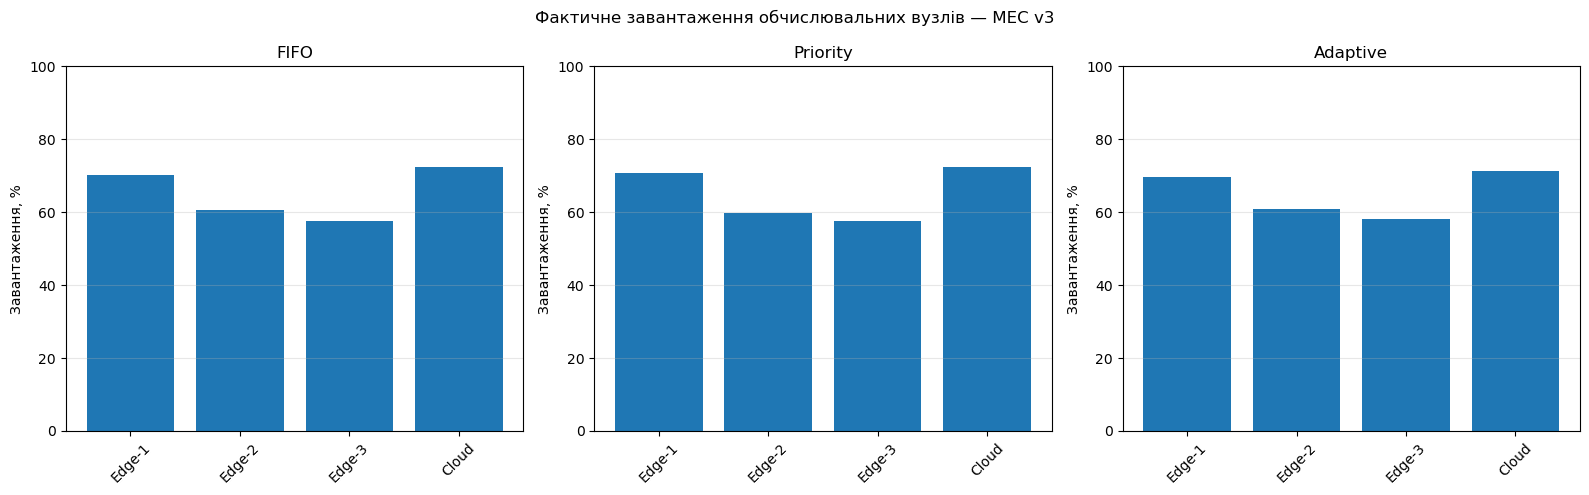

,Кількість завдань,"Середній час реакції, мс","95-й перцентиль, мс","Середній час очікування, мс","Виконано вчасно, %",Порушення дедлайну,"Середнє перевищення дедлайну, мс"
FIFO,2487.0,426.96,1306.50,111.67,51.47,1207.0,182.09
Priority,2487.0,462.41,1498.52,147.16,50.14,1240.0,196.21
Adaptive v3,2487.0,433.58,1392.02,119.45,54.80,1124.0,205.14
Adaptive v3.1,2487.0,450.83,1496.93,135.36,54.32,1136.0,222.03
Adaptive v3.2,2487.0,431.15,1372.40,117.16,54.68,1127.0,202.79


,Завдань,Середній_час_реакції,Середній_час_очікування,Вчасно_відсотків
type,,,,
T1,841,306.39,220.76,55.05
T2,891,844.02,83.90,16.27
T3,755,82.86,41.02,99.60


,Сервер,Кількість завдань,"Час роботи, мс","Завантаження, %"
0,Edge-1,712,209167.257692,69.599297
1,Edge-2,616,183055.308458,60.910684
2,Edge-3,467,173944.022106,57.878952
3,Cloud,692,214704.627158,71.441828


,Eta,Кількість завдань,"Середній час реакції, мс","95-й перцентиль, мс","Середній час очікування, мс","Виконано вчасно, %",Порушення дедлайну,"Середнє перевищення дедлайну, мс"
0,0.5,2487,431.15,1372.4,117.16,54.68,1127,202.79
1,1.0,2487,431.15,1372.4,117.16,54.68,1127,202.79
2,1.5,2487,431.15,1372.4,117.16,54.68,1127,202.79
3,2.0,2487,431.15,1372.4,117.16,54.68,1127,202.79
4,3.0,2487,431.15,1372.4,117.16,54.68,1127,202.79


Сигнатура функції:
(tasks, algorithm='Adaptive', alpha=1.0, beta=4.0, gamma=0.5, eta=1.0, aging_interval=500, max_priority=5, utilization_window=10000)

Фрагменти коду з eta:
5:     beta=4.0,
7:     eta=1.0,
52:             best_score = float("inf")
140:                         eta = 1.0
142:                         score = (
145:                             + beta * normalized_tardiness
147:                             - eta * effective_priority / max_priority
154:                             best_score = score
Eta 1.0: змінено призначень серверів — 0
Eta 1.5: змінено призначень серверів — 0
Eta 2.0: змінено призначень серверів — 0
Eta 3.0: змінено призначень серверів — 0


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import heapq

from dataclasses import dataclass
from collections import defaultdict

@dataclass
class TaskV3:
    id: int
    task_type: str
    arrival: float
    data_mb: float
    compute_mops: float
    priority: int
    deadline: float


def generate_tasks_v3(
    duration_sec=300,
    arrival_rate=8,
    seed=42
):
    rng = np.random.default_rng(seed)

    tasks = []
    current_time = 0.0
    task_id = 0

    probabilities = [0.35, 0.35, 0.30]

    while True:
        current_time += rng.exponential(1 / arrival_rate)

        if current_time > duration_sec:
            break

        task_type = rng.choice(
            ["T1", "T2", "T3"],
            p=probabilities
        )

        if task_type == "T1":
            data_mb = rng.uniform(0.2, 1.0)
            compute = rng.uniform(20, 80)

        elif task_type == "T2":
            data_mb = rng.uniform(5, 20)
            compute = rng.uniform(200, 700)

        else:
            data_mb = rng.uniform(0.05, 0.5)
            compute = rng.uniform(5, 30)

        config = TASK_TYPES[task_type]

        priority = config["priority"]
        deadline = config["deadline"]

        # Критичне відхилення параметрів вантажу
        if task_type == "T3" and rng.random() < 0.05:
            priority = 3
            deadline = 200

        tasks.append(
            TaskV3(
                id=task_id,
                task_type=task_type,
                arrival=current_time * 1000,
                data_mb=data_mb,
                compute_mops=compute,
                priority=priority,
                deadline=deadline
            )
        )

        task_id += 1

    return tasks

def execution_time_v3(task, server):

    transfer_time = (
        server["latency"]
        + task.data_mb / server["bandwidth"] * 1000
    )

    computation_time = (
        task.compute_mops
        / server["performance"] * 1000
    )

    return transfer_time + computation_time

def calculate_utilization_v3(
    busy_intervals,
    current_time,
    window=10000
):

    window_start = max(0, current_time - window)
    actual_window = current_time - window_start

    if actual_window <= 0:
        return 0.0

    busy_duration = 0.0

    for start, end in busy_intervals:

        overlap_start = max(start, window_start)
        overlap_end = min(end, current_time)

        if overlap_end > overlap_start:
            busy_duration += overlap_end - overlap_start

    return min(
        1.0,
        busy_duration / actual_window
    )

def simulate_v3(
    tasks,
    algorithm="Adaptive",
    alpha=1.0,
    beta=4.0,
    gamma=0.5,
    eta=1.0,
    aging_interval=500,
    max_priority=5,
    utilization_window=10000
):

    # Події: час, тип, номер, об'єкт
    events = []

    for task in tasks:
        heapq.heappush(
            events,
            (task.arrival, 0, task.id, "arrival", task)
        )

    waiting = []
    free_servers = set(range(len(SERVERS)))

    busy_intervals = defaultdict(list)

    results = []
    sequence = 0

    current_time = 0.0

    while events:

        current_time = events[0][0]

        # Обробка всіх подій одного моменту
        while events and events[0][0] == current_time:

            _, _, _, event_type, obj = heapq.heappop(events)

            if event_type == "arrival":
                waiting.append(obj)

            elif event_type == "completion":
                free_servers.add(obj)

        # Диспетчеризація
        while waiting and free_servers:

            selected_task = None
            selected_server = None
            best_score = float("inf")

            available = sorted(free_servers)

            if algorithm == "FIFO":

                selected_task = min(
                    waiting,
                    key=lambda t: (t.arrival, t.id)
                )

                selected_server = min(
                    available,
                    key=lambda j: execution_time_v3(
                        selected_task, SERVERS[j]
                    )
                )

            elif algorithm == "Priority":

                selected_task = min(
                    waiting,
                    key=lambda t: (
                        -t.priority,
                        t.arrival,
                        t.id
                    )
                )

                selected_server = min(
                    available,
                    key=lambda j: execution_time_v3(
                        selected_task, SERVERS[j]
                    )
                )

            elif algorithm == "Adaptive":

                for task in waiting:

                    waiting_time = (
                        current_time - task.arrival
                    )

                    effective_priority = min(
                        max_priority,
                        task.priority
                        + waiting_time / aging_interval
                    )

                    for j in available:

                        server = SERVERS[j]

                        execution = execution_time_v3(
                            task, server
                        )

                        response = (
                            waiting_time + execution
                        )

                        tardiness = max(
                            0,
                            response - task.deadline
                        )

                        utilization = calculate_utilization_v3(
                            busy_intervals[j],
                            current_time,
                            utilization_window
                        )

                        # Прогнозоване завантаження
                        projected_utilization = min(
                            1.0,
                            utilization
                            + execution / utilization_window
                        )

                        normalized_response = (
                            response / task.deadline
                        )

                        normalized_tardiness = (
                            tardiness / task.deadline
                        )

                        

                        score = (
                            alpha * normalized_response

                            + beta * normalized_tardiness

                            - eta * effective_priority / max_priority

                            + gamma * projected_utilization
                        )

                        if score < best_score:

                            best_score = score
                            selected_task = task
                            selected_server = j

            else:
                raise ValueError(
                    "Невідомий алгоритм планування"
                )

            # Призначення завдання
            waiting.remove(selected_task)
            free_servers.remove(selected_server)

            server = SERVERS[selected_server]

            execution = execution_time_v3(
                selected_task, server
            )

            start_time = current_time
            completion_time = start_time + execution

            waiting_time = (
                start_time - selected_task.arrival
            )

            response_time = (
                completion_time - selected_task.arrival
            )

            busy_intervals[selected_server].append(
                (start_time, completion_time)
            )

            results.append({
                "task_id": selected_task.id,
                "type": selected_task.task_type,
                "priority": selected_task.priority,
                "server": server["name"],
                "arrival": selected_task.arrival,
                "start": start_time,
                "completion": completion_time,
                "execution": execution,
                "waiting": waiting_time,
                "response": response_time,
                "deadline": selected_task.deadline,
                "on_time": (
                    response_time <= selected_task.deadline
                ),
                "tardiness": max(
                    0,
                    response_time - selected_task.deadline
                )
            })

            sequence += 1

            heapq.heappush(
                events,
                (
                    completion_time,
                    1,
                    sequence,
                    "completion",
                    selected_server
                )
            )

    return pd.DataFrame(results), busy_intervals

def calculate_metrics_v3(df):

    return {
        "Кількість завдань": len(df),

        "Середній час реакції, мс":
            df["response"].mean(),

        "95-й перцентиль, мс":
            df["response"].quantile(0.95),

        "Середній час очікування, мс":
            df["waiting"].mean(),

        "Виконано вчасно, %":
            df["on_time"].mean() * 100,

        "Порушення дедлайну":
            (~df["on_time"]).sum(),

        "Середнє перевищення дедлайну, мс":
            df["tardiness"].mean()
    }


def metrics_by_type_v3(df):

    return (
        df.groupby("type")
        .agg(
            Завдань=("task_id", "count"),
            Середній_час_реакції=("response", "mean"),
            Середній_час_очікування=("waiting", "mean"),
            Вчасно_відсотків=("on_time", "mean")
        )
        .assign(
            Вчасно_відсотків=lambda x:
                x["Вчасно_відсотків"] * 100
        )
        .round(2)
    )

test_tasks_v3 = generate_tasks_v3(
    duration_sec=300,
    arrival_rate=8,
    seed=42
)

v3_fifo, load_fifo = simulate_v3(
    test_tasks_v3,
    "FIFO"
)

v3_priority, load_priority = simulate_v3(
    test_tasks_v3,
    "Priority"
)

v3_adaptive, load_adaptive = simulate_v3(
    test_tasks_v3,
    "Adaptive"
)

comparison_v3 = pd.DataFrame({
    "FIFO": calculate_metrics_v3(v3_fifo),
    "Priority": calculate_metrics_v3(v3_priority),
    "Adaptive": calculate_metrics_v3(v3_adaptive)
}).T

display(comparison_v3.round(2))

print("FIFO")
display(metrics_by_type_v3(v3_fifo))

print("Priority")
display(metrics_by_type_v3(v3_priority))

print("Adaptive")
display(metrics_by_type_v3(v3_adaptive))

def server_utilization_v3(df):

    makespan = df["completion"].max()

    result = []

    for server in SERVERS:

        server_tasks = df[
            df["server"] == server["name"]
        ]

        busy = server_tasks["execution"].sum()

        utilization = (
            busy / makespan * 100
            if makespan > 0 else 0
        )

        result.append({
            "Сервер": server["name"],
            "Кількість завдань": len(server_tasks),
            "Час роботи, мс": busy,
            "Завантаження, %": utilization
        })

    return pd.DataFrame(result)


print("FIFO")
display(server_utilization_v3(v3_fifo))

print("Priority")
display(server_utilization_v3(v3_priority))

print("Adaptive")
display(server_utilization_v3(v3_adaptive))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

datasets = [
    ("FIFO", v3_fifo),
    ("Priority", v3_priority),
    ("Adaptive", v3_adaptive)
]

for ax, (name, df) in zip(axes, datasets):

    metrics = server_utilization_v3(df)

    ax.bar(
        metrics["Сервер"],
        metrics["Завантаження, %"]
    )

    ax.set_title(name)
    ax.set_ylabel("Завантаження, %")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Фактичне завантаження обчислювальних вузлів — MEC v3")
plt.tight_layout()
plt.show()

v3_adaptive_32, load_adaptive_32 = simulate_v3(
    test_tasks_v3,
    algorithm="Adaptive",
    alpha=1.0,
    beta=4.0,
    gamma=0.5,
    aging_interval=500,
    max_priority=3,
    utilization_window=10000
)

comparison_32 = pd.DataFrame({
    "FIFO": calculate_metrics_v3(v3_fifo),
    "Priority": calculate_metrics_v3(v3_priority),
    "Adaptive v3": calculate_metrics_v3(v3_adaptive),
    "Adaptive v3.1": calculate_metrics_v3(v3_adaptive_31),
    "Adaptive v3.2": calculate_metrics_v3(v3_adaptive_32)
}).T

display(comparison_32.round(2))

display(metrics_by_type_v3(v3_adaptive_32))

display(server_utilization_v3(v3_adaptive_32))

eta_values = [0.5, 1.0, 1.5, 2.0, 3.0]

eta_results = []

for eta_value in eta_values:

    df, _ = simulate_v3(
        test_tasks_v3,
        algorithm="Adaptive",
        alpha=1.0,
        beta=4.0,
        gamma=0.5,
        eta=eta_value,
        aging_interval=500,
        max_priority=3
    )

    metrics = calculate_metrics_v3(df)

    eta_results.append({
        "Eta": eta_value,
        **metrics
    })

eta_df = pd.DataFrame(eta_results)

display(eta_df.round(2))


import inspect

print("Сигнатура функції:")
print(inspect.signature(simulate_v3))

print("\nФрагменти коду з eta:")

source = inspect.getsource(simulate_v3)

for line_number, line in enumerate(source.splitlines(), 1):
    if "eta" in line or "score =" in line:
        print(f"{line_number}: {line}")

eta_values = [0.5, 1.0, 1.5, 2.0, 3.0]

eta_results = []
eta_assignments = {}

for eta_value in eta_values:

    df, _ = simulate_v3(
        test_tasks_v3,
        algorithm="Adaptive",
        alpha=1.0,
        beta=4.0,
        gamma=0.5,
        eta=eta_value,
        aging_interval=500,
        max_priority=3
    )

    metrics = calculate_metrics_v3(df)

    eta_results.append({
        "Eta": eta_value,
        **metrics
    })

    eta_assignments[eta_value] = df[
        ["task_id", "server"]
    ].sort_values("task_id").reset_index(drop=True)

eta_df = pd.DataFrame(eta_results)

display(eta_df.round(2))

for eta_value in eta_values[1:]:

    different = (
        eta_assignments[0.5]["server"]
        != eta_assignments[eta_value]["server"]
    ).sum()

    print(
        f"Eta {eta_value}: "
        f"змінено призначень — {different}"
    )




